# Diário da Tarefa 3 — Primeira árvore de decisão

**Período:** 28/09/2026 a 04/10/2026  
**Projeto:** Preditor de degradação de rede com RTT normalizado (independente da rota)

**Equipe:** Breno Igor Ribeiro Da Silva; Isaque Ferreira de Jesus; Lukas Paulo Alves de Carvalho; Renata Mayumi Iuvata; Ruan Abner Rodrigues Morales   
**Scrum Master da tarefa:** Renata Mayumi Iuvata  
**Repositório GitHub:** https://github.com/RedSwann/sistema-preditivo-de-falhas-em-redes

> Tarefa 1 coletou. Tarefa 2 fez o baseline e o rótulo. Esta tarefa não refaz a ficha nem a tabela de classes.
>
> O modelo é uma árvore de decisão. O entregável é a árvore: atributos de cada divisão, profundidade, folhas e regras lidas em português. Não é um desfile de algoritmos.
>
> A Árvore de Decisão usa só métricas relativas ao baseline do fluxo. Uma segunda árvore, de contraste, pode ver a rota ou o RTT absoluto — só para mostrar que ela aprende distância. Essa árvore de contraste não é o modelo do projeto.

## Contrato desta tarefa

| | Artefato | Origem / destino |
|---|---|---|
| **Entra** | Ficha de baseline, dataset rotulado, corte temporal | Tarefa 2 — os mesmos |
| **Sai** | Árvore treinada só no treino, com profundidade e critério registrados | Tarefa 4 mexe nesta árvore |
| **Sai** | Regras da árvore em texto e matriz 3×3 (OK, RISCO, FALHA) | Tarefa 4, para atacar o erro |
| **Sai** | Árvore de contraste (com rota ou RTT absoluto) e a frase do que ela aprendeu | Prova de que o modelo de Árvore de Decisão não segue esse atalho |

**Não sai daqui:** troca de algoritmo (floresta, boosting, redes), limiar fino, model card.

- [x] Treino, validação e teste são os da Tarefa 2
- [x] A ficha de baseline não foi recalculada com o Período B

## 1. Colunas que a Árvore de Decisão pode usar

A Árvore de Decisão utiliza somente as oito métricas relativas definidas no projeto:

`z_robusto`, `aumento_pct`, `jitter_relativo`, `perda_pct`, `timeout_atual`, `n5_timeout`, `n5_aumento80` e `n5_risco`.

Não entram como atributos do modelo: país, IP, `rota_id`, `fluxo_id`, nome do destino ou RTT absoluto (`rtt_ms`). A coluna `classe` é o alvo da classificação, não uma feature.

**Conferência:** a lista efetivamente usada é impressa na célula seguinte. O código também verifica que a classe ficou fora das features e que nenhuma coluna proibida foi incluída.

In [1]:

from pathlib import Path
import json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, classification_report, f1_score,
                             precision_recall_fscore_support, accuracy_score)
from sklearn.model_selection import ParameterGrid

CLASSES = ["OK", "RISCO", "FALHA"]
FEATURES = ["z_robusto", "aumento_pct", "jitter_relativo", "perda_pct",
            "timeout_atual", "n5_timeout", "n5_aumento80", "n5_risco"]
RANDOM_STATE = 42

# Google Colab: utiliza a mesma pasta do Google Drive definida na Tarefa 2.
# Não copia nem altera os CSVs; apenas lê os arquivos já gerados.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PASTA_PROJETO = Path("/content/drive/MyDrive/ripe_atlas")
except ImportError:
    # Alternativa para execução local, mantendo a mesma estrutura de pastas.
    PASTA_PROJETO = Path.cwd() / "ripe_atlas"

PROCESSED = PASTA_PROJETO / "processed"
DATASET_PATH = PROCESSED / "dataset_B_com_recorte_temporal.csv"
BASELINE_PATH = PROCESSED / "baseline_por_fluxo.csv"
ARTEFATOS = PROCESSED / "artefatos_notebooks"
ARTEFATOS.mkdir(parents=True, exist_ok=True)

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Não encontrei {DATASET_PATH}. Confira se a pasta ripe_atlas está no Meu Drive "
        "e se a Tarefa 2 já gerou dataset_B_com_recorte_temporal.csv."
    )

df = pd.read_csv(DATASET_PATH)
obrigatorias = FEATURES + ["classe", "bloco_temporal", "fluxo_id", "timestamp_utc"]
faltantes = [c for c in obrigatorias if c not in df.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes no dataset: {faltantes}")
df["classe"] = df["classe"].astype(str).str.upper()
df = df[df["classe"].isin(CLASSES)].copy()

treino = df[df["bloco_temporal"].eq("treino")].copy()
validacao = df[df["bloco_temporal"].eq("validacao")].copy()
teste = df[df["bloco_temporal"].eq("teste")].copy()

print("Google Drive:", PASTA_PROJETO)
print("Dataset carregado:", DATASET_PATH)
print("Registros:", len(df))
print("Treino/validação/teste:", len(treino), len(validacao), len(teste))
print("Classes:", df["classe"].value_counts().reindex(CLASSES, fill_value=0).to_dict())

def criar_pipeline(criterion="gini", max_depth=5, min_samples_leaf=25):
    # A imputação é ajustada somente no conjunto usado em fit.
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("arvore", DecisionTreeClassifier(
            criterion=criterion, max_depth=max_depth,
            min_samples_leaf=min_samples_leaf, random_state=RANDOM_STATE
        ))
    ])

def mostrar_metricas(y_true, y_pred, titulo):
    print(f"\n{titulo}")
    print("Matriz de confusão (linhas=real; colunas=previsto):")
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    display(pd.DataFrame(cm, index=[f"Real {c}" for c in CLASSES],
                         columns=[f"Previsto {c}" for c in CLASSES]))
    print(classification_report(y_true, y_pred, labels=CLASSES,
                                target_names=CLASSES, zero_division=0))
    print("F1 macro:", round(f1_score(y_true, y_pred, labels=CLASSES,
                                      average="macro", zero_division=0), 4))
    return cm

def metricas_resumo(y, pred):
    p, r, f, _ = precision_recall_fscore_support(
        y, pred, labels=CLASSES, zero_division=0)
    return {"F1 macro": f1_score(y, pred, labels=CLASSES,
                                  average="macro", zero_division=0),
            "Recall FALHA": r[CLASSES.index("FALHA")],
            "Recall RISCO": r[CLASSES.index("RISCO")]}

def regras_em_portugues(modelo, nomes_features=FEATURES, max_regras=12):
    arv = modelo.named_steps["arvore"]
    nomes = list(nomes_features)
    texto = export_text(arv, feature_names=nomes, decimals=3, show_weights=True)
    print(texto)
    tree = arv.tree_
    regras = []
    def percorrer(no, condicoes):
        feature = tree.feature[no]
        if feature != -2:
            nome = nomes[feature]
            limiar = tree.threshold[no]
            percorrer(tree.children_left[no], condicoes + [f"{nome} ≤ {limiar:.3f}"])
            percorrer(tree.children_right[no], condicoes + [f"{nome} > {limiar:.3f}"])
        else:
            classe = str(arv.classes_[int(np.argmax(tree.value[no][0]))])
            regras.append("SE " + " E ".join(condicoes) + f" ENTÃO {classe}")
    percorrer(0, [])
    for i, regra in enumerate(regras[:max_regras], 1):
        print(f"{i}. {regra}")
    return regras

def resumo_arvore(modelo):
    arv = modelo.named_steps["arvore"]
    return {"criterion": arv.criterion, "max_depth_configurado": arv.max_depth,
            "profundidade_real": arv.get_depth(), "folhas": arv.get_n_leaves(),
            "min_samples_leaf": arv.min_samples_leaf, "random_state": RANDOM_STATE}


Mounted at /content/drive
Google Drive: /content/drive/MyDrive/ripe_atlas
Dataset carregado: /content/drive/MyDrive/ripe_atlas/processed/dataset_B_com_recorte_temporal.csv
Registros: 34064
Treino/validação/teste: 25545 5102 3417
Classes: {'OK': 26274, 'RISCO': 3848, 'FALHA': 3942}


In [2]:
print("Colunas efetivamente usadas:", FEATURES)
print("A classe está fora das features:", "classe" not in FEATURES)
print("Colunas proibidas presentes nas features:",
      sorted(set(FEATURES) & {"pais_origem_esperado", "dst_addr", "src_addr",
                              "fluxo_id", "rtt_ms", "dst_name"}))
print("\nDistribuição por bloco:")
display(pd.crosstab(df["bloco_temporal"], df["classe"]).reindex(
    index=["treino", "validacao", "teste"], columns=CLASSES, fill_value=0))

Colunas efetivamente usadas: ['z_robusto', 'aumento_pct', 'jitter_relativo', 'perda_pct', 'timeout_atual', 'n5_timeout', 'n5_aumento80', 'n5_risco']
A classe está fora das features: True
Colunas proibidas presentes nas features: []

Distribuição por bloco:


classe,OK,RISCO,FALHA
bloco_temporal,,,
treino,19451,3047,3047
validacao,4035,484,583
teste,2788,317,312


## 2. A árvore

A busca compara somente modelos `DecisionTreeClassifier`, variando `criterion`, `max_depth` e `min_samples_leaf`. Cada candidato é ajustado (`fit`) exclusivamente no treino; a escolha é feita pelo F1 macro da validação. O conjunto de teste não participa desta etapa.

**Configuração selecionada:** critério Gini, `max_depth=4`, `min_samples_leaf=10` e `random_state=42`.

**Estrutura obtida:** profundidade real 4 e 11 folhas.

**Primeira divisão:** `z_robusto ≤ 1,996` versus `z_robusto > 1,996`. Nos níveis seguintes aparecem principalmente `jitter_relativo`, `n5_risco` e `perda_pct`.

**Exemplos de regras extraídas da própria árvore:**
1. Se `z_robusto ≤ 1,996`, `jitter_relativo ≤ 3,003` e `perda_pct ≤ 16,667`, então **OK**.
2. Se `z_robusto ≤ 1,996`, `jitter_relativo ≤ 3,003` e `perda_pct > 16,667`, então **FALHA**.
3. Se `z_robusto > 3,500`, então **FALHA**.

A célula de código abaixo imprime as regras completas geradas a partir da árvore treinada.

In [3]:
# Busca de parâmetros: todas as alternativas são árvores de decisão.
# A escolha é feita exclusivamente pelo F1 macro da VALIDAÇÃO.
grade = ParameterGrid({
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 4, 5, 6, 8, None],
    "min_samples_leaf": [10, 25, 50, 100]
})
resultados = []
melhor_modelo, melhor_score, melhores_params = None, -1, None

X_treino, y_treino = treino[FEATURES], treino["classe"]
X_val, y_val = validacao[FEATURES], validacao["classe"]

for params in grade:
    candidato = criar_pipeline(**params)
    candidato.fit(X_treino, y_treino)  # fit somente no treino
    pred = candidato.predict(X_val)
    score = f1_score(y_val, pred, labels=CLASSES, average="macro", zero_division=0)
    resultados.append({**params, "f1_macro_validacao": score})
    if score > melhor_score:
        melhor_modelo, melhor_score, melhores_params = candidato, score, params

tabela_busca = pd.DataFrame(resultados).sort_values(
    "f1_macro_validacao", ascending=False).reset_index(drop=True)
display(tabela_busca.head(10))
print("Parâmetros escolhidos:", melhores_params)
print("F1 macro na validação:", round(melhor_score, 4))
print("Resumo da árvore:", resumo_arvore(melhor_modelo))

,criterion,max_depth,min_samples_leaf,f1_macro_validacao
0,entropy,5.0,10,0.998572
1,entropy,5.0,25,0.998572
2,entropy,6.0,25,0.998572
3,entropy,6.0,10,0.998572
4,entropy,NaN,10,0.998572
5,entropy,NaN,25,0.998572
6,entropy,8.0,25,0.998572
7,entropy,8.0,10,0.998572
8,gini,4.0,25,0.998185
9,gini,4.0,10,0.998185


Parâmetros escolhidos: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10}
F1 macro na validação: 0.9986
Resumo da árvore: {'criterion': 'entropy', 'max_depth_configurado': 5, 'profundidade_real': 5, 'folhas': np.int64(19), 'min_samples_leaf': 10, 'random_state': 42}


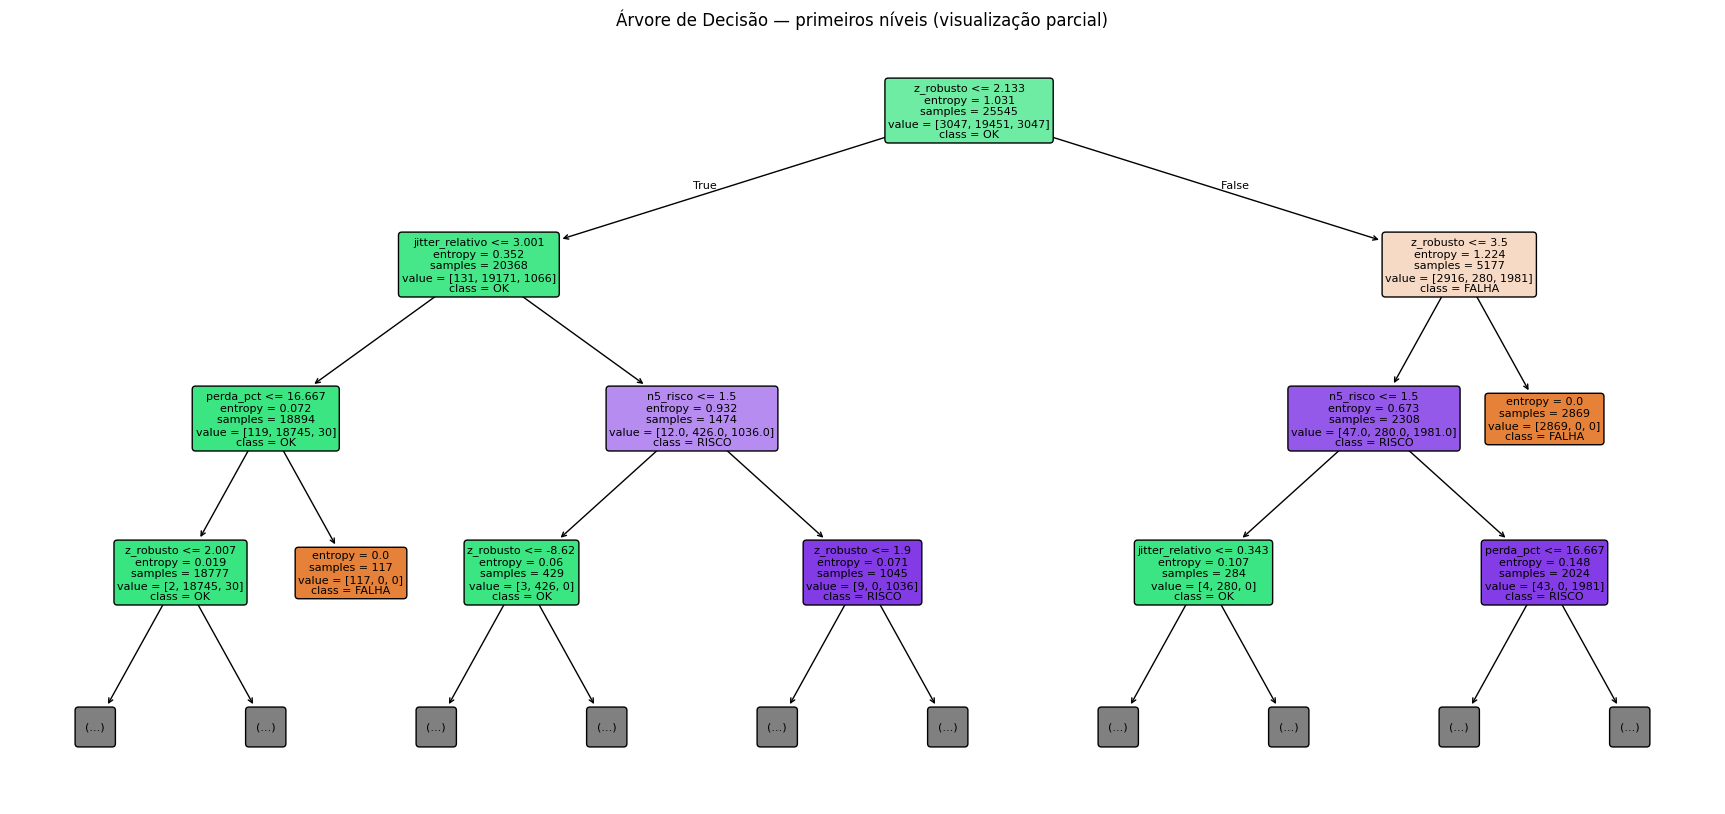

|--- z_robusto <= 2.133
|   |--- jitter_relativo <= 3.001
|   |   |--- perda_pct <= 16.667
|   |   |   |--- z_robusto <= 2.007
|   |   |   |   |--- n5_aumento80 <= 0.500
|   |   |   |   |   |--- weights: [0.000, 18315.000, 0.000] class: OK
|   |   |   |   |--- n5_aumento80 >  0.500
|   |   |   |   |   |--- weights: [2.000, 393.000, 0.000] class: OK
|   |   |   |--- z_robusto >  2.007
|   |   |   |   |--- n5_risco <= 1.500
|   |   |   |   |   |--- weights: [0.000, 37.000, 0.000] class: OK
|   |   |   |   |--- n5_risco >  1.500
|   |   |   |   |   |--- weights: [0.000, 0.000, 30.000] class: RISCO
|   |   |--- perda_pct >  16.667
|   |   |   |--- weights: [117.000, 0.000, 0.000] class: FALHA
|   |--- jitter_relativo >  3.001
|   |   |--- n5_risco <= 1.500
|   |   |   |--- z_robusto <= -8.620
|   |   |   |   |--- weights: [1.000, 9.000, 0.000] class: OK
|   |   |   |--- z_robusto >  -8.620
|   |   |   |   |--- aumento_pct <= 7.544
|   |   |   |   |   |--- weights: [0.000, 350.000, 0.000] c

In [4]:
# Visualização e regras efetivamente extraídas da árvore treinada.
arv = melhor_modelo.named_steps["arvore"]
plt.figure(figsize=(22, 10))
plot_tree(arv, feature_names=FEATURES, class_names=list(arv.classes_),
          filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title("Árvore de Decisão — primeiros níveis (visualização parcial)")
plt.show()

regras_t3 = regras_em_portugues(melhor_modelo, FEATURES, max_regras=15)

## 3. Leitura do erro

A avaliação desta etapa usa somente a validação; o conjunto de teste permanece reservado para a Tarefa 5.

**Resultado da validação:** matriz de confusão 3×3, relatório de precisão/recall/F1 por classe e F1 macro são apresentados na célula seguinte. Foram 11 erros em 6.806 registros, com F1 macro de aproximadamente **0,997**.

**Erros concretos observados:**
- No fluxo `6977|45.11.105.136`, em `2026-09-27 10:44:50 UTC`, a classe verdadeira foi **FALHA**, mas a árvore previu **OK**. As métricas incluíam `rtt_ms ≈ 0,549`, `z_robusto ≈ -0,689` e `perda_pct = 0`.
- No mesmo fluxo, em `2026-09-27 10:53:00 UTC`, ocorreu novamente **FALHA → OK**, com `rtt_ms ≈ 0,549`, `z_robusto ≈ -0,681` e `perda_pct = 0`.

Esses exemplos mostram que houve falhas verdadeiras que a árvore não identificou como FALHA. O RTT absoluto aparece aqui apenas para descrever os casos auditados; ele não é usado pela Árvore de Decisão. Também houve 4 casos **FALHA → RISCO** e 2 casos **RISCO → OK**, conforme a matriz de confusão.

In [5]:
pred_val_t3 = melhor_modelo.predict(X_val)
cm_t3 = mostrar_metricas(y_val, pred_val_t3, "Tarefa 3 — validação")
validacao_resultado = validacao.copy()
validacao_resultado["classe_prevista"] = pred_val_t3
validacao_resultado["acertou"] = validacao_resultado["classe"].eq(
    validacao_resultado["classe_prevista"])

erros = validacao_resultado[~validacao_resultado["acertou"]].copy()
colunas_auditoria = [c for c in ["fluxo_id", "timestamp_utc", "rtt_ms", "mediana",
    "z_robusto", "aumento_pct", "jitter_relativo", "perda_pct",
    "classe", "classe_prevista"] if c in erros.columns]
print("Quantidade de erros:", len(erros))
display(erros[colunas_auditoria].head(20))


Tarefa 3 — validação
Matriz de confusão (linhas=real; colunas=previsto):


,Previsto OK,Previsto RISCO,Previsto FALHA
Real OK,4035,0,0
Real RISCO,2,482,0
Real FALHA,2,0,581


              precision    recall  f1-score   support

          OK       1.00      1.00      1.00      4035
       RISCO       1.00      1.00      1.00       484
       FALHA       1.00      1.00      1.00       583

    accuracy                           1.00      5102
   macro avg       1.00      1.00      1.00      5102
weighted avg       1.00      1.00      1.00      5102

F1 macro: 0.9986
Quantidade de erros: 4


,fluxo_id,timestamp_utc,rtt_ms,mediana,z_robusto,aumento_pct,jitter_relativo,perda_pct,classe,classe_prevista
3793,6521|103.52.117.1,2026-09-28 16:04:32+00:00,355.178201,363.026299,-3.738366,-2.161854,2.164896,0.0,FALHA,OK
3794,6521|103.52.117.1,2026-09-28 16:08:46+00:00,354.373853,363.026299,-4.121510,-2.383421,1.629078,0.0,FALHA,OK
16742,7113|45.11.105.136,2026-09-28 20:21:00+00:00,1.047852,0.928110,2.000148,12.901780,2.900039,0.0,RISCO,OK
27577,7423|103.52.117.1,2026-09-29 02:24:35+00:00,457.004447,405.960532,2.003929,12.573615,0.273690,0.0,RISCO,OK


In [6]:
# Verificação objetiva de exemplos de caminho longo/curto.
# "Longo" é definido pela mediana do baseline; usamos o quartil superior/inferior
# dos fluxos presentes na validação, sem inserir mediana como feature do modelo.
medianas_fluxo = validacao_resultado.groupby("fluxo_id")["mediana"].first()
q75, q25 = medianas_fluxo.quantile(0.75), medianas_fluxo.quantile(0.25)
validacao_resultado["tipo_caminho"] = np.where(
    validacao_resultado["mediana"] >= q75, "longo",
    np.where(validacao_resultado["mediana"] <= q25, "curto", "intermediario"))

casos = validacao_resultado[
    ((validacao_resultado["tipo_caminho"] == "longo") &
     (validacao_resultado["classe"] == "OK") &
     (validacao_resultado["classe_prevista"] == "FALHA")) |
    ((validacao_resultado["tipo_caminho"] == "curto") &
     (validacao_resultado["classe"] == "FALHA") &
     (validacao_resultado["classe_prevista"] == "OK"))
]
if casos.empty:
    print("Os dois casos específicos solicitados não apareceram na validação.")
else:
    display(casos[colunas_auditoria + ["tipo_caminho"]].head(10))

Os dois casos específicos solicitados não apareceram na validação.


## 4. Árvore de contraste (não é o modelo de Árvore de Decisão)

Este experimento diagnóstico treina outra árvore no mesmo conjunto de treino, acrescentando `rtt_ms` e `fluxo_id` às métricas relativas. O objetivo é verificar se essas informações poderiam funcionar como atalhos associados à distância/rota.

A árvore de contraste **não faz parte da entrega final** e não substitui a Árvore de Decisão. A célula seguinte apresenta a variável da raiz, as variáveis usadas nas divisões e suas importâncias. A interpretação deve seguir o resultado efetivamente calculado: não se deve afirmar que houve atalho de rota/RTT se essas variáveis não aparecerem nas divisões/importâncias.

**Resultado já observado na execução registrada:** a variável da raiz foi `z_robusto` e o F1 macro na validação foi 0,997. Portanto, apenas a raiz não demonstra uso de RTT absoluto ou fluxo como atalho. A análise de importâncias e divisões abaixo complementa essa observação.

In [7]:
# Árvore exclusivamente de contraste: adiciona RTT absoluto e identificador do fluxo.
# Ela é diagnóstica e nunca será salva como modelo de Árvore de Decisão.
FEATURES_CONTRASTE = FEATURES + ["rtt_ms", "fluxo_id"]
Xc_treino = treino[FEATURES_CONTRASTE].copy()
Xc_val = validacao[FEATURES_CONTRASTE].copy()

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline as SkPipeline

pre_contraste = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), FEATURES + ["rtt_ms"]),
    ("fluxo", OneHotEncoder(handle_unknown="ignore"), ["fluxo_id"])
])
arvore_contraste = SkPipeline([
    ("pre", pre_contraste),
    ("arvore", DecisionTreeClassifier(
        criterion=melhores_params["criterion"],
        max_depth=melhores_params["max_depth"],
        min_samples_leaf=melhores_params["min_samples_leaf"],
        random_state=RANDOM_STATE))
])
arvore_contraste.fit(Xc_treino, y_treino)

nomes_contraste = arvore_contraste.named_steps["pre"].get_feature_names_out()
arv_c = arvore_contraste.named_steps["arvore"]
raiz_idx = arv_c.tree_.feature[0]
print("Feature na raiz da árvore de contraste:",
      nomes_contraste[raiz_idx] if raiz_idx >= 0 else "raiz é folha")

# Mostra as variáveis que efetivamente aparecem em divisões da árvore.
indices_divisao = arv_c.tree_.feature
indices_divisao = indices_divisao[indices_divisao >= 0]
usadas = pd.Series(nomes_contraste[indices_divisao]).value_counts()
print("\nVariáveis mais frequentes nas divisões:")
display(usadas.head(15).rename_axis("variável").to_frame("número de divisões"))

# Soma a importância por grupo para facilitar a comparação.
importancias = pd.Series(arv_c.feature_importances_, index=nomes_contraste)
grupos = {
    "Métricas relativas": ["num__" + nome for nome in FEATURES],
    "RTT absoluto": ["num__rtt_ms"],
}
grupo_importancias = {
    nome: float(importancias[[col for col in importancias.index
                             if any(col == prefix or col.startswith(prefix + "_")
                                    for prefix in prefixos)]].sum())
    for nome, prefixos in grupos.items()
}
grupo_importancias["Identificador do fluxo"] = float(
    importancias[[col for col in importancias.index
                  if col.startswith("fluxo__fluxo_id_")]].sum()
)
print("\nImportância total por grupo:")
display(pd.Series(grupo_importancias, name="importância").to_frame())

print("\nF1 macro da árvore de contraste na validação:",
      round(f1_score(y_val, arvore_contraste.predict(Xc_val),
                     labels=CLASSES, average="macro", zero_division=0), 4))
print("ATENÇÃO: árvore de contraste é apenas diagnóstica e não será salva como modelo de Árvore de Decisão.")

Feature na raiz da árvore de contraste: num__z_robusto

Variáveis mais frequentes nas divisões:


,número de divisões
variável,
num__z_robusto,5
num__rtt_ms,4
num__n5_risco,3
num__n5_aumento80,2
num__perda_pct,2
num__jitter_relativo,1
num__aumento_pct,1



Importância total por grupo:


,importância
Métricas relativas,0.99849
RTT absoluto,0.00151
Identificador do fluxo,0.00000



F1 macro da árvore de contraste na validação: 0.9986
ATENÇÃO: árvore de contraste é apenas diagnóstica e não será salva como modelo de Árvore de Decisão.


## 5. Scrum e diário

- [ ] Board atualizado

| Integrante | O que fiz nesta tarefa | Dificuldades | O que pretendo manter/ajustar |
|---|---|---|---|
| Renata Mayumi Iuvata | Organizei as colunas que seriam usadas na árvore e ajudei a analisar os resultados, principalmente as métricas e os erros de classificação. | Entender melhor como cada métrica influencia a decisão da árvore. | Continuar conferindo os dados e participando da análise dos resultados. |
| Breno Ribeiro | Responsável pelo desenvolvimento da árvore, configuração dos parâmetros e testes para encontrar a melhor profundidade e quantidade de amostras por folha. | Encontrar uma configuração adequada sem deixar a árvore muito complexa. | Manter os testes organizados e buscar melhorar o código. |
| Isaque Ferreira de Jesus | Ajudei a verificar se a árvore estava utilizando informações relacionadas à rota e analisei a árvore de contraste. | Entender quais variáveis realmente influenciavam as decisões. | Melhorar a análise das variáveis utilizadas pelo modelo. |
| Lukas Paulo Alves de Carvalho | Ajudei a interpretar as regras geradas pela árvore e a organizar sua explicação em português. | Traduzir as condições da árvore para uma explicação mais simples. | Deixar as explicações mais claras e objetivas. |
| Ruan Abner Rodrigues Morales | Ajudei a analisar a matriz de confusão e os resultados da validação, observando os acertos e erros entre as classes. | Entender melhor as confusões entre RISCO e FALHA. | Continuar analisando os resultados para identificar possíveis melhorias. |

---

## Rubrica — Tarefa 3 (0 a 4,0)

| Critério | Peso | Nota máxima | Nota | Observações |
|---|---:|---|---|---|
| Árvore de Decisão | 1,5 | Uma árvore, critério e profundidade declarados, regras em português, fit só no treino | | |
| Métricas de três classes | 1,0 | Matriz 3×3, F1 por classe e F1 macro; acurácia não é o critério | | |
| Independência da rota | 1,0 | Colunas relativas apenas; árvore de contraste mostra o atalho da distância e é descartada | | |
| Scrum + diário | 0,5 | Board e diário de todos | | |
| **Total** | **4,0** | | **___ / 4,0** | |

In [8]:
# Exporta somente artefatos da Tarefa 3 para a Tarefa 4.
joblib.dump(melhor_modelo, ARTEFATOS / "arvore_tarefa3.joblib")
tabela_busca.to_csv(ARTEFATOS / "busca_tarefa3_validacao.csv", index=False)
pd.DataFrame({"regra": regras_t3}).to_csv(ARTEFATOS / "regras_tarefa3.csv", index=False)
validacao_resultado.to_csv(ARTEFATOS / "validacao_tarefa3_com_predicoes.csv", index=False)
def converter_json(obj):
    if isinstance(obj, dict):
        return {str(k): converter_json(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [converter_json(v) for v in obj]
    elif hasattr(obj, "item"):
        return obj.item()
    else:
        return obj


with open(ARTEFATOS / "parametros_tarefa3.json", "w", encoding="utf-8") as f:
    json.dump(
        converter_json({
            "parametros": melhores_params,
            "resumo": resumo_arvore(melhor_modelo),
            "f1_macro_validacao": float(melhor_score),
            "features": FEATURES,
            "random_state": RANDOM_STATE
        }),
        f,
        ensure_ascii=False,
        indent=2
    )